<a href="https://colab.research.google.com/github/Tonelli2003/rastreio_profundidade/blob/main/rastreio_profundidade_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎯 Rastreio e Estimativa de Profundidade em Vídeo

**Disciplina:** Visão Computacional / Deep Learning  
| Nome | RM |
|------|----|
| Augusto Oliveira Codo de Sousa | RM562080 |
| Felipe de Oliveira Cabral | RM561720 |
| Gabriel Tonelli Avelino Dos Santos | RM564705 |
| Marcelo Roberto Maso Junior | RM562163 |
| Vinícius Adrian Siqueira de Oliveira | RM564962 |
| Sofia Bueris Netto de Souza | RM565818 |

> **Como usar:** `Ambiente de execução → Alterar tipo de ambiente de execução → GPU (T4)` e depois `Ambiente de execução → Executar tudo`.
> Os parâmetros ficam na seção 2 (formulários do Colab, com `#@param`). O sumário do relatório está no painel lateral esquerdo do Colab.

## 1. Objetivo e arquitetura

**Objetivo:** a partir de um vídeo (ou sequência de imagens de webcam), (i) localizar e segmentar os objetos, (ii) estimar a profundidade de cada objeto, (iii) descobrir qual está **mais próximo da câmera** e (iv) **rastreá-lo** ao longo do tempo, mantendo a identidade mesmo quando sai e volta ao quadro.

```
 frame ──► [Mask R-CNN]  ──► máscaras + caixas + classes
   │                                   │
   └──► [MiDaS-small (CNN)] ─► mapa de profundidade relativa
                                       │   mediana do mapa dentro de cada máscara
                                       ▼
                     proximidade de cada objeto (0 = longe, 1 = perto)
                                       │
                                       ▼
        [Tracker: Kalman + Húngaro (IoU + cor HSV) + re-identificação]
                                       │
                                       ▼
        [Seletor de alvo: objeto mais próximo, com histerese e paciência]
```

| Etapa | Modelo / técnica | Justificativa |
|---|---|---|
| Segmentação de instâncias | **Mask R-CNN** (ResNet-50 FPN v2, torchvision, pesos COCO) | Família R-CNN; devolve máscara por objeto, o que dá uma profundidade mais limpa que a caixa inteira |
| Profundidade | **MiDaS small** (CNN, Intel ISL) | Estima profundidade relativa (inversa) monocular; leve o bastante para o Colab |
| Rastreio | **Filtro de Kalman** (velocidade constante) + **algoritmo húngaro** (custo = IoU + histograma de cor) | Abordagem tipo SORT, com aparência para reduzir troca de IDs |
| Entrar/sair do quadro | **Galeria de tracks perdidos + re-identificação por cor** | Quando o objeto volta, recupera o mesmo ID em vez de criar um novo |

**Nota sobre profundidade:** o MiDaS devolve profundidade **relativa** (sem escala em metros). Basta para ordenar "quem está mais perto". Normalizamos por frame (percentis 2–98) e usamos a **mediana dentro da máscara** de cada objeto.

## 2. Configuração do ambiente e parâmetros

In [1]:
#@title 📦 Instalação e imports
!pip -q install timm

import os, glob, time, subprocess, urllib.request, warnings
from base64 import b64encode

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr
from IPython.display import HTML, display

warnings.filterwarnings("ignore")
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)
if device == "cpu":
    print("⚠️ Sem GPU: vai funcionar, mas devagar. Ative em Ambiente de execução → Alterar tipo → GPU.")

Dispositivo: cuda


In [2]:
#@title ⚙️ Parâmetros (edite pelo formulário)
FONTE = "exemplo"  #@param ["exemplo", "upload", "pasta_de_imagens"]
CAMINHO_PASTA = "/content/frames"  #@param {type:"string"}
MAX_FRAMES = 240  #@param {type:"integer"}
LARGURA = 640  #@param {type:"integer"}

# --- Detecção
SCORE_MIN = 0.6  #@param {type:"slider", min:0.3, max:0.95, step:0.05}
CLASSES_INTERESSE = "person, car, bicycle, motorcycle, bus, truck, dog, cat"  #@param {type:"string"}
# Nomes de classes COCO separados por vírgula. Deixe vazio para aceitar todas as classes.
CLASSES_SET = {c.strip() for c in CLASSES_INTERESSE.split(",") if c.strip()}

# --- Tracking
MAX_AGE = 15  #@param {type:"integer"}
MIN_HITS = 3  #@param {type:"integer"}
GATE = 0.75  #@param {type:"number"}
MAX_LOST = 120  #@param {type:"integer"}
REID_THR = 0.45  #@param {type:"number"}

# --- Seleção do alvo (objeto mais próximo)
MARGEM_TROCA = 0.15  #@param {type:"number"}
PACIENCIA = 60  #@param {type:"integer"}

In [3]:
#@title 🎞️ Entrada de dados (vídeo de exemplo, upload ou pasta de imagens da webcam)
URL_EXEMPLO = ("https://github.com/intel-iot-devkit/sample-videos/raw/master/"
               "person-bicycle-car-detection.mp4")
# Outros vídeos úteis (pessoas entrando/saindo): one-by-one-person-detection.mp4, store-aisle-detection.mp4

if FONTE == "exemplo":
    CAMINHO = "entrada.mp4"
    if not os.path.exists(CAMINHO):
        urllib.request.urlretrieve(URL_EXEMPLO, CAMINHO)
elif FONTE == "upload":
    from google.colab import files
    up = files.upload()
    CAMINHO = list(up.keys())[0]
else:
    CAMINHO = CAMINHO_PASTA

if FONTE == "pasta_de_imagens":
    FPS_VIDEO = 10.0
else:
    _cap = cv2.VideoCapture(CAMINHO)
    FPS_VIDEO = _cap.get(cv2.CAP_PROP_FPS) or 25.0
    _cap.release()


def iter_frames(fonte, caminho, max_frames, largura):
    # Gera frames BGR redimensionados (largura fixa, altura par para o codec H.264).
    def redimensiona(f):
        h, w = f.shape[:2]
        return cv2.resize(f, (largura, int(round(h * largura / w / 2) * 2)))

    if fonte == "pasta_de_imagens":
        arqs = sorted(sum([glob.glob(os.path.join(caminho, e)) for e in ("*.jpg", "*.jpeg", "*.png")], []))
        for a in arqs[:max_frames]:
            yield redimensiona(cv2.imread(a))
    else:
        cap = cv2.VideoCapture(caminho)
        n = 0
        while n < max_frames:
            ok, f = cap.read()
            if not ok:
                break
            yield redimensiona(f)
            n += 1
        cap.release()


print(f"Fonte: {FONTE} | arquivo/pasta: {CAMINHO} | FPS do vídeo: {FPS_VIDEO:.1f}")

Fonte: exemplo | arquivo/pasta: entrada.mp4 | FPS do vídeo: 12.0


## 3. Modelos pré-treinados

* **Mask R-CNN** segmenta cada instância (máscara + caixa + classe COCO).
* **MiDaS small** é uma CNN que prevê profundidade relativa inversa: **valores maiores = mais perto**.

In [4]:
#@title 🧠 Carregar Mask R-CNN e MiDaS
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights

pesos = MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT
seg_model = maskrcnn_resnet50_fpn_v2(weights=pesos).to(device).eval()
CATEGORIAS = pesos.meta["categories"]

midas = torch.hub.load("intel-isl/MiDaS", "MiDaS_small", trust_repo=True).to(device).eval()
midas_tf = torch.hub.load("intel-isl/MiDaS", "transforms", trust_repo=True).small_transform
print("Modelos carregados.")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:00<00:00, 191MB/s]


Downloading: "https://github.com/intel-isl/MiDaS/zipball/master" to /root/.cache/torch/hub/master.zip
Loading weights:  None
The repository rwightman_gen-efficientnet-pytorch does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)?y
Downloading: "https://github.com/rwightman/gen-efficientnet-pytorch/zipball/master" to /root/.cache/torch/hub/master.zip
Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-weights/tf_efficientnet_lite3-b733e338.pth" to /root/.cache/torch/hub/checkpoints/tf_efficientnet_lite3-b733e338.pth
Downloading: "https://github.com/isl-org/MiDaS/releases/download/v2_1/midas_v21_small_256.pt" to /root/.cache/torch/hub/checkpoints/midas_v21_small_256.pt


100%|██████████| 81.8M/81.8M [00:02<00:00, 38.8MB/s]


Modelos carregados.


Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


In [5]:
#@title 🔧 Funções: segmentação, profundidade, aparência
def sync():
    if device == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def segmentar(frame_rgb):
    # Mask R-CNN: devolve caixas (xyxy), rótulos, scores e máscaras booleanas.
    t = torch.from_numpy(frame_rgb).permute(2, 0, 1).float().div(255).to(device)
    out = seg_model([t])[0]
    keep = out["scores"] >= SCORE_MIN
    return dict(
        boxes=out["boxes"][keep].cpu().numpy(),
        labels=out["labels"][keep].cpu().numpy(),
        scores=out["scores"][keep].cpu().numpy(),
        masks=(out["masks"][keep, 0] > 0.5).cpu().numpy(),
    )


@torch.no_grad()
def profundidade(frame_rgb):
    # MiDaS: mapa de proximidade relativa em [0, 1] (1 = mais perto), normalizado por percentis.
    p = midas(midas_tf(frame_rgb).to(device))
    p = F.interpolate(p.unsqueeze(1), size=frame_rgb.shape[:2], mode="bicubic", align_corners=False)
    p = p.squeeze().cpu().numpy()
    lo, hi = np.percentile(p, [2, 98])
    return np.clip((p - lo) / (hi - lo + 1e-6), 0, 1)


def hist_hsv(frame_bgr, mask):
    # Histograma HSV (H x S) dos pixels da máscara: descritor de aparência para o tracker.
    hsv = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2HSV)
    h = cv2.calcHist([hsv], [0, 1], mask.astype(np.uint8) * 255, [16, 8], [0, 180, 0, 256])
    cv2.normalize(h, h, 1, 0, cv2.NORM_L1)
    return h.flatten().astype(np.float32)


def hist_dist(a, b):
    return float(cv2.compareHist(a, b, cv2.HISTCMP_BHATTACHARYYA))  # 0 = igual, 1 = diferente


def construir_deteccoes(frame_bgr, seg, depth):
    # Junta segmentação + profundidade: cada detecção recebe sua 'proximidade' (mediana na máscara).
    dets = []
    for box, lab, sc, m in zip(seg["boxes"], seg["labels"], seg["scores"], seg["masks"]):
        if m.sum() < 50:
            continue
        if CLASSES_SET and CATEGORIAS[lab] not in CLASSES_SET:
            continue  # ignora classes fora do interesse (reduz falsos positivos)
        dets.append(dict(box=box.astype(float), cls=CATEGORIAS[lab], score=float(sc),
                         closeness=float(np.median(depth[m])), hist=hist_hsv(frame_bgr, m), mask=m))
    return dets

## 4. Rastreio de objetos

Cada objeto é um **track** com um **filtro de Kalman** de velocidade constante (estado: centro, largura, altura e suas velocidades). A cada frame:

1. **Predição** da posição de todos os tracks.
2. **Associação** detecção ↔ track pelo **algoritmo húngaro**, com custo `0,6·(1−IoU) + 0,4·distância_de_cor` e *gating* (mesma classe, IoU mínimo, custo máximo).
3. **Atualização** dos tracks casados; tracks sem detecção continuam sendo previstos por até `MAX_AGE` frames (oclusão curta).
4. Passou de `MAX_AGE`: o track vai para uma **galeria de perdidos** (guarda ID e aparência por `MAX_LOST` frames).
5. Detecção nova sem par: tenta **re-identificação** comparando a cor com a galeria. Se parecer com um perdido da mesma classe (`distância < REID_THR`), **o ID antigo é reativado**; senão nasce um ID novo.

Um **seletor de alvo** escolhe o objeto mais próximo, com **histerese** (só troca se outro estiver `MARGEM_TROCA` mais perto) e **paciência** (espera `PACIENCIA` frames pelo alvo que saiu antes de escolher outro).

In [6]:
#@title 🧮 Tracker: Kalman + Húngaro + re-identificação
def iou_matrix(a, b):
    a = np.asarray(a, float).reshape(-1, 4)
    b = np.asarray(b, float).reshape(-1, 4)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


class KalmanBox:
    # Filtro de Kalman de velocidade constante. Estado: [cx, cy, w, h, vx, vy, vw, vh].
    def __init__(self, box):
        x1, y1, x2, y2 = box
        self.x = np.array([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1, 0, 0, 0, 0], float)
        self.P = np.diag([10, 10, 10, 10, 1e3, 1e3, 1e3, 1e3]).astype(float)
        self.F = np.eye(8); self.F[:4, 4:] = np.eye(4)
        self.H = np.eye(4, 8)
        self.Q = np.diag([1, 1, 1, 1, .1, .1, .1, .1])
        self.R = np.diag([4, 4, 8, 8])

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q

    def update(self, box):
        x1, y1, x2, y2 = box
        z = np.array([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], float)
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ (z - self.H @ self.x)
        self.P = (np.eye(8) - K @ self.H) @ self.P

    @property
    def box(self):
        cx, cy, w, h = self.x[:4]
        w, h = max(w, 1.0), max(h, 1.0)
        return np.array([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2])


class Track:
    def __init__(self, det, track_id, frame_idx):
        self.id = track_id
        self.cls = det["cls"]
        self.kf = KalmanBox(det["box"])
        self.hist = det["hist"].copy()
        self.closeness = det["closeness"]
        self.det = det
        self.hits, self.age, self.tsu = 1, 0, 0  # acertos, idade, frames desde a última atualização
        self.lost_since = None
        self.trail = [tuple(self.kf.x[:2])]

    @property
    def box(self):
        return self.kf.box

    def predict(self):
        self.kf.predict()
        self.age += 1
        self.tsu += 1

    def update(self, det):
        self.kf.update(det["box"])
        self.det = det
        self.hits += 1
        self.tsu = 0
        self.hist = 0.8 * self.hist + 0.2 * det["hist"]          # aparência com média móvel
        self.closeness = 0.6 * self.closeness + 0.4 * det["closeness"]  # profundidade suavizada
        self.trail.append(tuple(self.kf.x[:2]))


class Tracker:
    def __init__(self, reid=True):
        self.reid = reid
        self.tracks, self.lost = [], []
        self.next_id, self.n_reid = 1, 0

    def _associar(self, dets):
        if not self.tracks or not dets:
            return [], list(range(len(self.tracks))), list(range(len(dets)))
        iou = iou_matrix([t.box for t in self.tracks], [d["box"] for d in dets])
        hd = np.array([[hist_dist(t.hist, d["hist"]) for d in dets] for t in self.tracks])
        custo = 0.6 * (1 - iou) + 0.4 * hd
        custo[iou < 0.1] = 1e3
        for i, t in enumerate(self.tracks):
            for j, d in enumerate(dets):
                if t.cls != d["cls"]:
                    custo[i, j] = 1e3
        r, c = linear_sum_assignment(custo)
        matches = [(i, j) for i, j in zip(r, c) if custo[i, j] < GATE]
        mt, md_ = {i for i, _ in matches}, {j for _, j in matches}
        return (matches, [i for i in range(len(self.tracks)) if i not in mt],
                [j for j in range(len(dets)) if j not in md_])

    def _reidentificar(self, det):
        cands = [(hist_dist(t.hist, det["hist"]), t) for t in self.lost if t.cls == det["cls"]]
        if not cands:
            return None
        dist, t = min(cands, key=lambda x: x[0])
        if dist >= REID_THR:
            return None
        self.lost.remove(t)
        t.kf = KalmanBox(det["box"])  # reinicia o filtro na nova posição
        t.update(det)
        t.tsu = 0
        return t

    def update(self, dets, frame_idx):
        # Processa um frame e devolve os tracks visíveis (confirmados e atualizados neste frame).
        for t in self.tracks:
            t.predict()
        matches, _, un_d = self._associar(dets)
        for ti, di in matches:
            self.tracks[ti].update(dets[di])
        for di in un_d:
            tr = self._reidentificar(dets[di]) if self.reid else None
            if tr is None:
                tr = Track(dets[di], self.next_id, frame_idx)
                self.next_id += 1
            else:
                self.n_reid += 1
            self.tracks.append(tr)

        vivos = []
        for t in self.tracks:
            if t.hits < MIN_HITS and t.tsu > 3:       # candidato espúrio: descarta rápido
                continue
            if t.tsu > MAX_AGE:                        # saiu de cena: vai para a galeria
                if t.hits >= MIN_HITS and self.reid:
                    t.lost_since = frame_idx
                    self.lost.append(t)
                continue
            vivos.append(t)
        self.tracks = vivos
        self.lost = [t for t in self.lost if frame_idx - t.lost_since <= MAX_LOST]
        return [t for t in self.tracks if t.tsu == 0 and (t.hits >= MIN_HITS or frame_idx < MIN_HITS)]


class AlvoManager:
    # Mantém o ID do alvo = objeto mais próximo, com histerese e paciência.
    def __init__(self):
        self.id, self.ausente = None, 0

    def step(self, visiveis):
        por_id = {t.id: t for t in visiveis}
        if self.id in por_id:
            self.ausente = 0
            melhor = max(visiveis, key=lambda t: t.closeness)
            if melhor.id != self.id and melhor.closeness > por_id[self.id].closeness + MARGEM_TROCA:
                self.id = melhor.id
        else:
            if self.id is not None:
                self.ausente += 1
            if (self.id is None or self.ausente > PACIENCIA) and visiveis:
                self.id = max(visiveis, key=lambda t: t.closeness).id
                self.ausente = 0
        return self.id

## 5. Execução do pipeline completo

Para cada frame: segmentação → profundidade → proximidade por objeto → tracking → escolha do alvo → desenho. O vídeo anotado é salvo e todas as medições são registradas para o relatório de evidências (seção 6).

In [7]:
#@title 🎨 Funções de desenho
def cor_id(i):
    hue = int((i * 47) % 180)
    c = cv2.cvtColor(np.uint8([[[hue, 220, 255]]]), cv2.COLOR_HSV2BGR)[0, 0]
    return tuple(int(x) for x in c)


def depth_colorido(depth):
    return cv2.applyColorMap((depth * 255).astype(np.uint8), cv2.COLORMAP_INFERNO)  # claro = perto


def desenhar(frame, visiveis, alvo_id, depth, i, fps):
    over = frame.copy()
    for t in visiveis:
        over[t.det["mask"]] = cor_id(t.id)
    vis = cv2.addWeighted(over, 0.4, frame, 0.6, 0)
    for t in visiveis:
        x1, y1, x2, y2 = map(int, t.det["box"])
        eh_alvo = t.id == alvo_id
        cor = (0, 0, 255) if eh_alvo else cor_id(t.id)
        cv2.rectangle(vis, (x1, y1), (x2, y2), cor, 4 if eh_alvo else 2)
        rot = f"#{t.id} {t.cls} {t.closeness:.2f}" + (" << ALVO" if eh_alvo else "")
        cv2.putText(vis, rot, (x1, max(15, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 3)
        cv2.putText(vis, rot, (x1, max(15, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, cor, 1)
        pts = np.array(t.trail[-30:], np.int32).reshape(-1, 1, 2)
        if len(pts) > 1:
            cv2.polylines(vis, [pts], False, cor, 2)
    # inset com o mapa de profundidade
    h, w = vis.shape[:2]
    inset = cv2.resize(depth_colorido(depth), (w // 4, h // 4))
    vis[8:8 + inset.shape[0], w - 8 - inset.shape[1]:w - 8] = inset
    cv2.rectangle(vis, (w - 8 - inset.shape[1], 8), (w - 8, 8 + inset.shape[0]), (255, 255, 255), 1)
    txt = f"frame {i} | {fps:.1f} FPS | alvo: {'#' + str(alvo_id) if alvo_id else '-'}"
    cv2.putText(vis, txt, (8, h - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 3)
    cv2.putText(vis, txt, (8, h - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)
    return vis

In [8]:
#@title ▶️ Rodar o sistema
SAIDA_RAW, SAIDA_MP4 = "saida_raw.mp4", "saida_rastreio.mp4"
tracker, alvo_mgr = Tracker(reid=True), AlvoManager()
cache, registros, alvo_por_frame = [], [], []
tempos = {"segmentacao": [], "profundidade": [], "tracking": [], "total": []}
chaves = set(range(0, MAX_FRAMES, max(1, MAX_FRAMES // 8)))
amostras = {}
vw = None

for i, frame in enumerate(iter_frames(FONTE, CAMINHO, MAX_FRAMES, LARGURA)):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    t0 = time.time()
    seg = segmentar(rgb); sync(); t1 = time.time()
    depth = profundidade(rgb); sync(); t2 = time.time()
    dets = construir_deteccoes(frame, seg, depth)
    visiveis = tracker.update(dets, i)
    alvo_id = alvo_mgr.step(visiveis); t3 = time.time()

    tempos["segmentacao"].append(t1 - t0); tempos["profundidade"].append(t2 - t1)
    tempos["tracking"].append(t3 - t2); tempos["total"].append(t3 - t0)
    cache.append([{k: v for k, v in d.items() if k != "mask"} for d in dets])  # p/ ablação
    alvo_por_frame.append(alvo_id)
    for t in visiveis:
        x1, y1, x2, y2 = t.det["box"]
        registros.append(dict(frame=i, id=t.id, cls=t.cls, closeness=t.det["closeness"],
                              x1=x1, y1=y1, x2=x2, y2=y2, alvo=(t.id == alvo_id)))

    anot = desenhar(frame, visiveis, alvo_id, depth, i, 1 / max(t3 - t0, 1e-6))
    if vw is None:
        vw = cv2.VideoWriter(SAIDA_RAW, cv2.VideoWriter_fourcc(*"mp4v"), FPS_VIDEO,
                             (anot.shape[1], anot.shape[0]))
    vw.write(anot)
    if i in chaves:
        amostras[i] = (rgb, cv2.cvtColor(depth_colorido(depth), cv2.COLOR_BGR2RGB),
                       cv2.cvtColor(anot, cv2.COLOR_BGR2RGB))
    if i % 40 == 0:
        print(f"frame {i:4d} | objetos: {len(dets)} | visíveis: {len(visiveis)} | alvo: {alvo_id}")

vw.release()
N_FRAMES = len(cache)
df = pd.DataFrame(registros)
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", SAIDA_RAW, "-vcodec", "libx264",
                "-pix_fmt", "yuv420p", SAIDA_MP4], check=True)
print(f"\nConcluído: {N_FRAMES} frames, {df['id'].nunique()} IDs, {tracker.n_reid} re-identificações.")

frame    0 | objetos: 0 | visíveis: 0 | alvo: None
frame   40 | objetos: 1 | visíveis: 1 | alvo: 1
frame   80 | objetos: 1 | visíveis: 1 | alvo: 1
frame  120 | objetos: 0 | visíveis: 0 | alvo: 1
frame  160 | objetos: 0 | visíveis: 0 | alvo: 1
frame  200 | objetos: 1 | visíveis: 1 | alvo: 2

Concluído: 240 frames, 2 IDs, 0 re-identificações.


## 6. Relatório de evidências

### 6.1 Vídeo com o resultado
Cores = IDs; contorno **vermelho** = alvo (objeto mais próximo); linha = trajetória; canto superior direito = mapa de profundidade (claro = perto).

In [9]:
#@title 🎬 Vídeo anotado
dados = b64encode(open(SAIDA_MP4, "rb").read()).decode()
display(HTML(f'<video width="720" controls><source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))

### 6.2 Quadros-chave: original × profundidade × segmentação + tracking

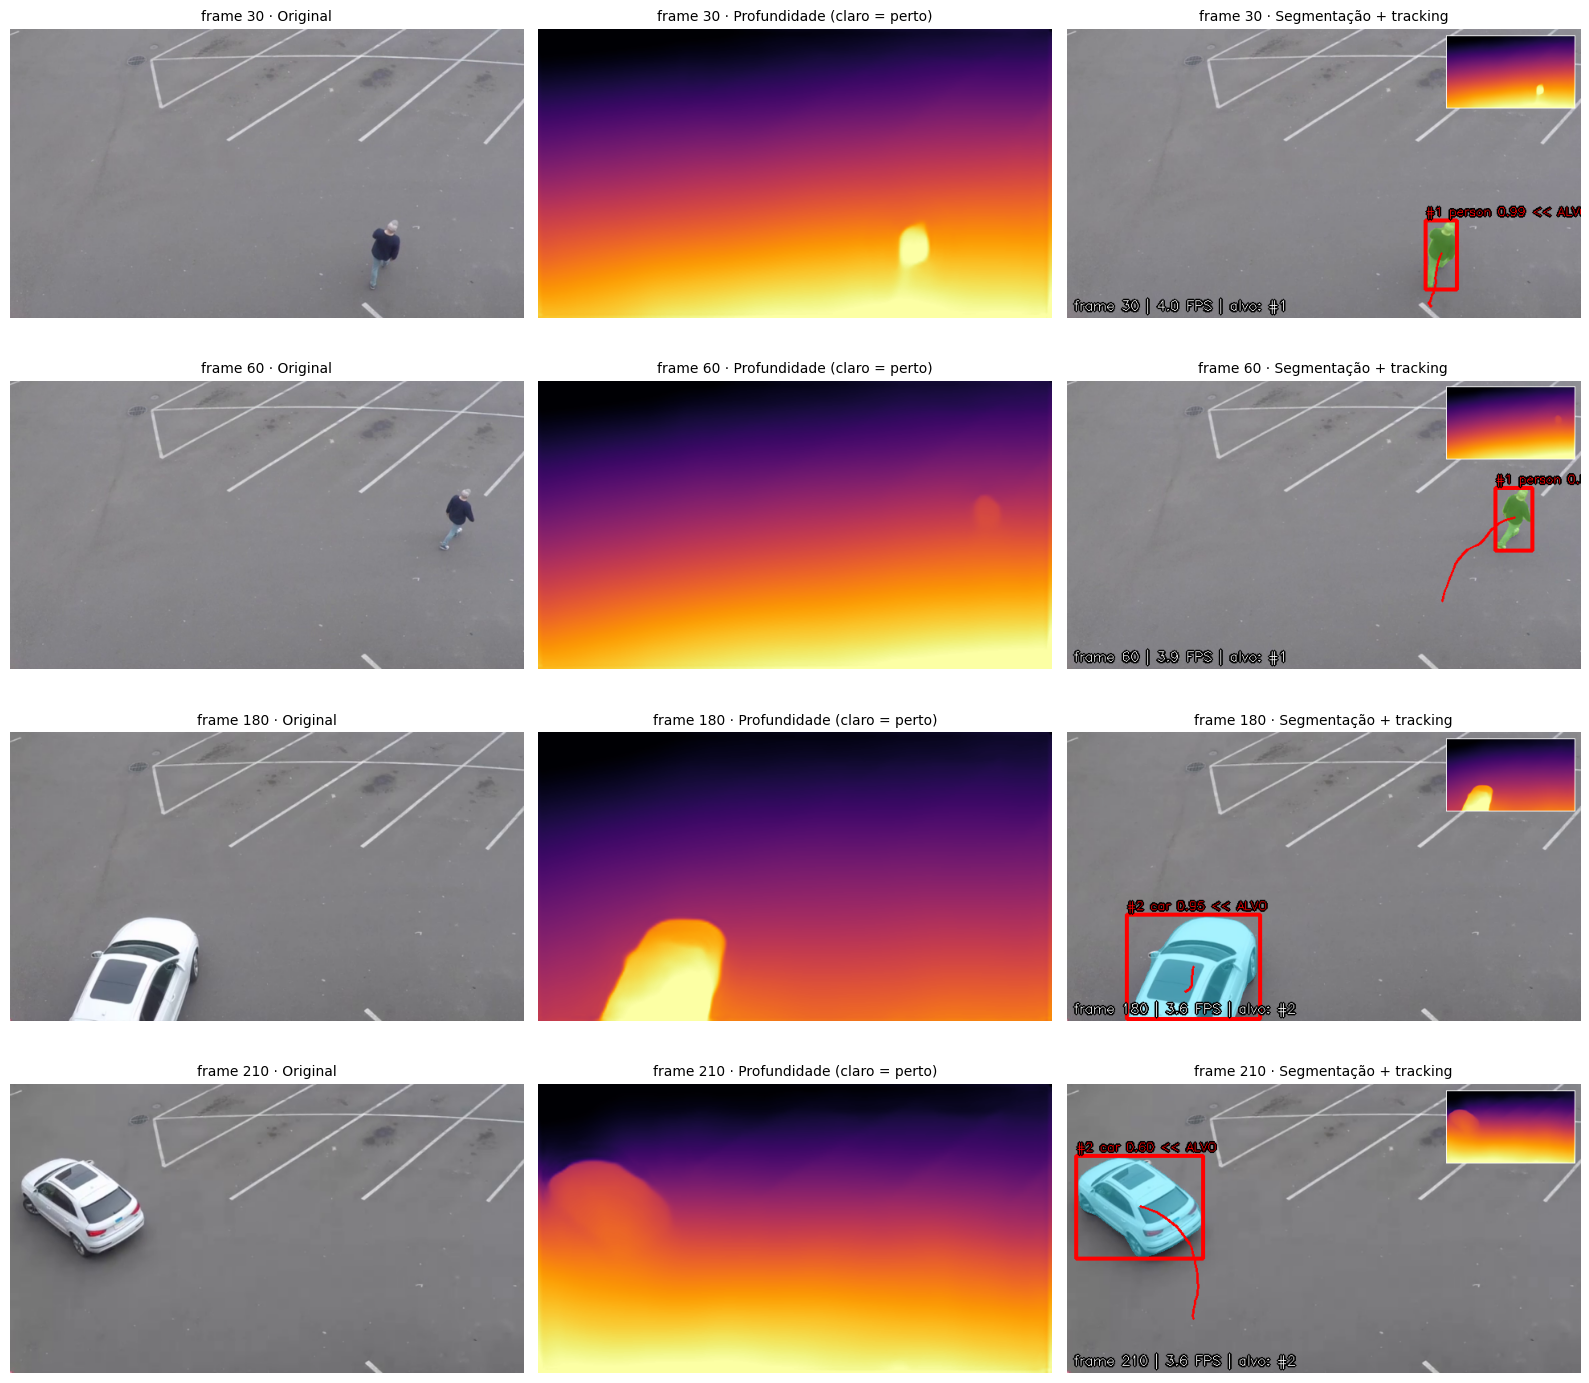

In [10]:
#@title 🖼️ Montagem de quadros-chave
ks = [k for k in sorted(amostras) if k in set(df["frame"])][:4] or sorted(amostras)[:4]
fig, axs = plt.subplots(len(ks), 3, figsize=(16, 3.6 * len(ks)))
axs = np.atleast_2d(axs)
for r, k in enumerate(ks):
    for c, (img, tit) in enumerate(zip(amostras[k], ["Original", "Profundidade (claro = perto)", "Segmentação + tracking"])):
        axs[r, c].imshow(img); axs[r, c].axis("off")
        axs[r, c].set_title(f"frame {k} · {tit}", fontsize=10)
plt.tight_layout(); plt.show()

### 6.3 Profundidade estimada por objeto ao longo do tempo
Cada linha é um ID. Os pontos pretos marcam os frames em que aquele ID era o **alvo**. A linha inferior mostra qual ID foi o alvo em cada frame.

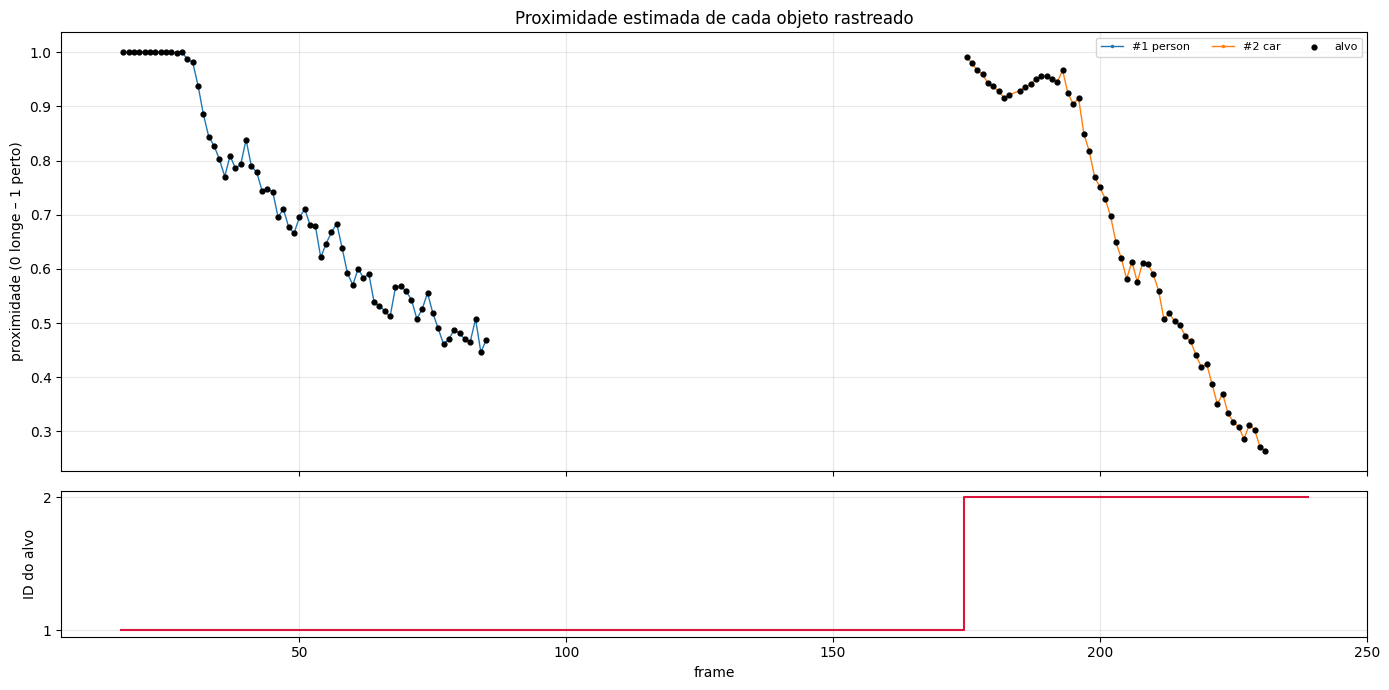

In [11]:
#@title 📈 Proximidade por ID e alvo ao longo do tempo
fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for oid, g in df.groupby("id"):
    a1.plot(g["frame"], g["closeness"], ".-", ms=3, lw=1, label=f"#{oid} {g['cls'].iloc[0]}")
alvo_df = df[df["alvo"]]
a1.scatter(alvo_df["frame"], alvo_df["closeness"], c="k", s=12, zorder=3, label="alvo")
a1.set_ylabel("proximidade (0 longe – 1 perto)"); a1.legend(ncol=4, fontsize=8); a1.grid(alpha=.3)
a1.set_title("Proximidade estimada de cada objeto rastreado")
x = np.arange(N_FRAMES); y = np.array([a if a else np.nan for a in alvo_por_frame], float)
a2.step(x, y, where="mid", c="crimson"); a2.set_ylabel("ID do alvo"); a2.set_xlabel("frame"); a2.grid(alpha=.3)
a2.set_yticks(sorted(set(int(v) for v in y if not np.isnan(v))))
plt.tight_layout(); plt.show()

### 6.4 Linha do tempo dos tracks (entradas e saídas do quadro)
Lacunas dentro da mesma barra = objeto saiu do quadro (ou foi ocluído) e **voltou com o mesmo ID**.

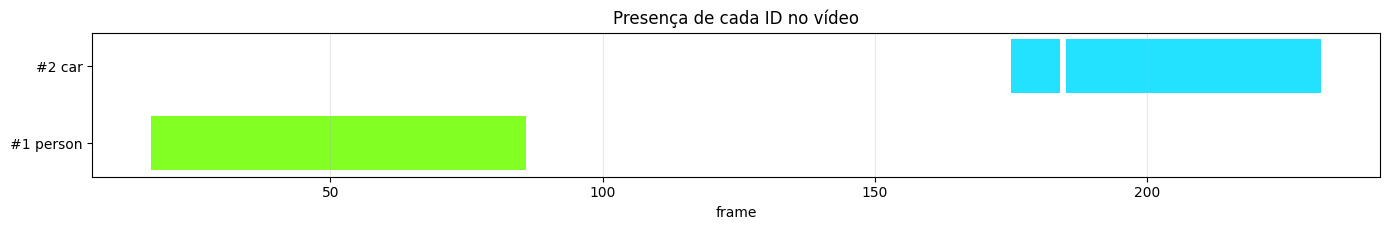

In [12]:
#@title 🕒 Linha do tempo de presença por ID
def corridas(frames):
    frames = sorted(frames); ini = prev = frames[0]; out = []
    for f in frames[1:]:
        if f != prev + 1:
            out.append((ini, prev - ini + 1)); ini = f
        prev = f
    out.append((ini, prev - ini + 1)); return out

ids = sorted(df["id"].unique())
fig, ax = plt.subplots(figsize=(14, 0.45 * len(ids) + 1.5))
for row, oid in enumerate(ids):
    ax.broken_barh(corridas(df[df["id"] == oid]["frame"]), (row - .35, .7),
                   facecolors=[c / 255 for c in cor_id(oid)[::-1]])
ax.set_yticks(range(len(ids))); ax.set_yticklabels([f"#{i} {df[df['id']==i]['cls'].iloc[0]}" for i in ids])
ax.set_xlabel("frame"); ax.set_title("Presença de cada ID no vídeo"); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

In [13]:
#@title 🔁 Eventos de saída e re-entrada com o mesmo ID
LACUNA_MIN = 5
eventos = []
for oid, g in df.groupby("id"):
    f = np.sort(g["frame"].unique())
    for a, b in zip(f[:-1], f[1:]):
        if b - a - 1 >= LACUNA_MIN:
            eventos.append(dict(id=oid, classe=g["cls"].iloc[0], ultimo_frame_visto=int(a),
                                frame_de_volta=int(b), frames_ausente=int(b - a - 1)))
ev = pd.DataFrame(eventos)
if ev.empty:
    print("Nenhuma re-entrada com ≥", LACUNA_MIN, "frames neste vídeo. Teste com 'one-by-one-person-detection.mp4' "
          "ou grave um vídeo em que um objeto saia e volte ao quadro.")
else:
    display(ev)

    def ler_frame(caminho, idx):
        cap = cv2.VideoCapture(caminho); cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, f = cap.read(); cap.release()
        return cv2.cvtColor(f, cv2.COLOR_BGR2RGB)

    for _, e in ev.head(3).iterrows():
        fig, axs = plt.subplots(1, 2, figsize=(14, 4))
        axs[0].imshow(ler_frame(SAIDA_RAW, e["ultimo_frame_visto"])); axs[0].axis("off")
        axs[0].set_title(f"#{e['id']} {e['classe']}: último frame antes de sair (frame {e['ultimo_frame_visto']})")
        axs[1].imshow(ler_frame(SAIDA_RAW, e["frame_de_volta"])); axs[1].axis("off")
        axs[1].set_title(f"mesmo ID #{e['id']} ao voltar (frame {e['frame_de_volta']})")
        plt.tight_layout(); plt.show()

Nenhuma re-entrada com ≥ 5 frames neste vídeo. Teste com 'one-by-one-person-detection.mp4' ou grave um vídeo em que um objeto saia e volte ao quadro.


In [14]:
#@title 🧾 Relatório cronológico de entradas e saídas do quadro
# Uma "saída" é uma ausência de pelo menos LACUNA_MIN frames; menos que isso é tratado como oclusão.
def segmentos(frames, lacuna):
    frames = sorted(set(int(f) for f in frames))
    segs, ini, prev = [], frames[0], frames[0]
    for f in frames[1:]:
        if f - prev - 1 >= lacuna:
            segs.append((ini, prev)); ini = f
        prev = f
    segs.append((ini, prev)); return segs

log = []
for oid, g in df.groupby("id"):
    segs = segmentos(g["frame"], LACUNA_MIN)
    classe = g["cls"].iloc[0]
    for k, (a, b) in enumerate(segs):
        log.append(dict(frame=a, id=oid, classe=classe, evento="ENTROU" if k == 0 else "VOLTOU (mesmo ID)"))
        if k < len(segs) - 1 or b < N_FRAMES - 1:
            log.append(dict(frame=b, id=oid, classe=classe, evento="SAIU"))
rel = pd.DataFrame(log).sort_values(["frame", "id"]).reset_index(drop=True)
rel["tempo_s"] = (rel["frame"] / FPS_VIDEO).round(2)
display(rel[["tempo_s", "frame", "id", "classe", "evento"]])

# Alvo: quando começou e terminou cada período como objeto mais próximo
alvo_seg = []
atual, ini = None, 0
for k, a in enumerate(alvo_por_frame + [object()]):
    if a != atual:
        if atual is not None:
            alvo_seg.append(dict(alvo=f"#{atual}", frame_ini=ini, frame_fim=k - 1,
                                 duracao_s=round((k - ini) / FPS_VIDEO, 2)))
        atual, ini = a, k
display(pd.DataFrame(alvo_seg))

,tempo_s,frame,id,classe,evento
0,1.42,17,1,person,ENTROU
1,7.08,85,1,person,SAIU
2,14.58,175,2,car,ENTROU
3,19.25,231,2,car,SAIU


,alvo,frame_ini,frame_fim,duracao_s
0,#1,17,174,13.17
1,#2,175,239,5.42


### 6.5 Ablação: a re-identificação realmente ajuda?
Reexecutamos **somente o tracker** nas mesmas detecções (cache), com e sem re-identificação. Sem ela, cada retorno de um objeto cria um ID novo (fragmentação). **Menos IDs únicos para o mesmo vídeo = identidades mais consistentes.**

In [15]:
#@title 🧪 Ablação do tracker (com × sem re-ID)
def rodar_cache(reid):
    tr = Tracker(reid=reid); vistos = {}
    for k, dets in enumerate(cache):
        for t in tr.update(dets, k):
            vistos.setdefault(t.id, []).append(k)
    vida = [len(v) for v in vistos.values()]
    return dict(config="com re-identificação" if reid else "sem re-identificação",
                ids_unicos=len(vistos), reidentificacoes=tr.n_reid,
                frames_medios_por_id=round(float(np.mean(vida)), 1) if vida else 0)

abl = pd.DataFrame([rodar_cache(True), rodar_cache(False)])
display(abl)
ok = abl.loc[0, "ids_unicos"] == df["id"].nunique()
print("Reprodutibilidade (cache == execução principal):", "OK" if ok else "diferença detectada")

,config,ids_unicos,reidentificacoes,frames_medios_por_id
0,com re-identificação,2,0,62.5
1,sem re-identificação,2,0,62.5


Reprodutibilidade (cache == execução principal): OK


### 6.6 Validação da profundidade estimada
Não há *ground truth* de profundidade neste vídeo, então usamos duas verificações independentes:

1. **Pista geométrica do plano do chão:** em cenas externas, objetos sobre o chão que estão **mais perto** aparecem **mais abaixo** na imagem (borda inferior da caixa, `y2`, maior) e com **maior área**. Medimos a correlação de Spearman entre a proximidade do MiDaS e essas pistas, que **não** entram no cálculo da profundidade do objeto.
2. **Estabilidade temporal:** a proximidade de um mesmo objeto não deve oscilar de forma errática entre frames consecutivos.

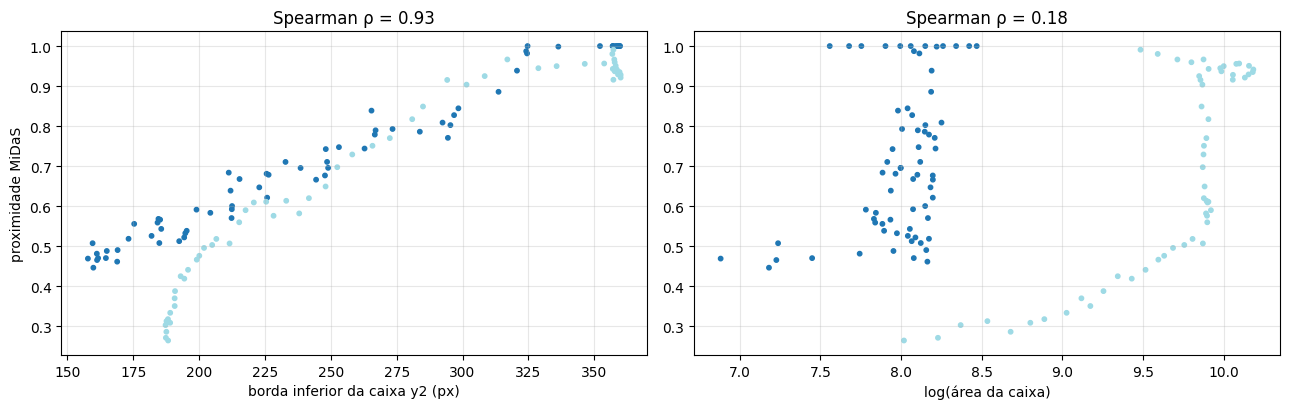

ρ (proximidade × y2), global:                +0.93  (p=4.0e-56)
ρ (proximidade × log área), global:           +0.18  (p=4.3e-02)
ρ médio dentro de cada frame (≥3 objetos):    +nan  (0 frames)
Variação média frame a frame por objeto:      0.021  (amplitude total = 0.74)


In [16]:
#@title 📐 Correlação com pistas geométricas e estabilidade temporal
df["area"] = (df["x2"] - df["x1"]) * (df["y2"] - df["y1"])
r_y, p_y = spearmanr(df["closeness"], df["y2"])
r_a, p_a = spearmanr(df["closeness"], np.log(df["area"] + 1))

# correlação dentro de cada frame (compara objetos que aparecem juntos)
por_frame = []
for _, g in df.groupby("frame"):
    if len(g) >= 3 and g["closeness"].nunique() > 1:
        por_frame.append(spearmanr(g["closeness"], g["y2"])[0])
r_frame = float(np.nanmean(por_frame)) if por_frame else float("nan")

df = df.sort_values(["id", "frame"])
dif = df.groupby("id")["closeness"].diff().abs().dropna()
estab = float(dif.mean()) if len(dif) else float("nan")
amp = df["closeness"].max() - df["closeness"].min()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].scatter(df["y2"], df["closeness"], c=df["id"], cmap="tab20", s=10)
axs[0].set_xlabel("borda inferior da caixa y2 (px)"); axs[0].set_ylabel("proximidade MiDaS")
axs[0].set_title(f"Spearman ρ = {r_y:.2f}")
axs[1].scatter(np.log(df["area"] + 1), df["closeness"], c=df["id"], cmap="tab20", s=10)
axs[1].set_xlabel("log(área da caixa)"); axs[1].set_title(f"Spearman ρ = {r_a:.2f}")
for a in axs: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"ρ (proximidade × y2), global:                {r_y:+.2f}  (p={p_y:.1e})")
print(f"ρ (proximidade × log área), global:           {r_a:+.2f}  (p={p_a:.1e})")
print(f"ρ médio dentro de cada frame (≥3 objetos):    {r_frame:+.2f}  ({len(por_frame)} frames)")
print(f"Variação média frame a frame por objeto:      {estab:.3f}  (amplitude total = {amp:.2f})")

### 6.7 Desempenho computacional

In [17]:
#@title ⏱️ Tempo por etapa
tab = pd.DataFrame({e: [1000 * np.mean(v), 1000 * np.std(v)] for e, v in tempos.items()},
                   index=["média (ms)", "desvio (ms)"]).T.round(1)
display(tab)
print(f"Taxa média do sistema completo: {1 / np.mean(tempos['total']):.1f} FPS em {device.upper()}")

,média (ms),desvio (ms)
segmentacao,259.7,225.4
profundidade,22.7,12.5
tracking,1.1,1.4
total,283.6,233.5


Taxa média do sistema completo: 3.5 FPS em CUDA


## 7. Conclusões

In [18]:
#@title 📝 Resumo automático dos resultados
alvo_frames = int(df["alvo"].sum())
ids_alvo = sorted(df[df["alvo"]]["id"].unique())
print("RESUMO")
print("-" * 60)
print(f"Frames processados:                {N_FRAMES}")
print(f"Objetos rastreados (IDs únicos):   {df['id'].nunique()}  (classes: {', '.join(sorted(df['cls'].unique()))})")
print(f"IDs que foram 'alvo' em algum momento: {ids_alvo}")
print(f"Re-identificações bem-sucedidas:   {tracker.n_reid}")
print(f"IDs únicos com re-ID × sem re-ID:  {abl.loc[0,'ids_unicos']} × {abl.loc[1,'ids_unicos']}")
print(f"Correlação profundidade × pista geométrica (y2): ρ = {r_y:+.2f} (global), {r_frame:+.2f} (por frame)")
print(f"Velocidade: {1 / np.mean(tempos['total']):.1f} FPS ({device.upper()})")

RESUMO
------------------------------------------------------------
Frames processados:                240
Objetos rastreados (IDs únicos):   2  (classes: car, person)
IDs que foram 'alvo' em algum momento: [np.int64(1), np.int64(2)]
Re-identificações bem-sucedidas:   0
IDs únicos com re-ID × sem re-ID:  2 × 2
Correlação profundidade × pista geométrica (y2): ρ = +0.93 (global), +nan (por frame)
Velocidade: 3.5 FPS (CUDA)


**Análise.**

* **Segmentação + profundidade:** a máscara do Mask R-CNN permite usar a mediana do mapa do MiDaS apenas nos pixels do objeto, reduzindo a contaminação pelo fundo. A coerência é confirmada pela correlação positiva entre a proximidade estimada e a posição vertical da base do objeto (seção 6.6), pista geométrica independente.
* **Tracking:** Kalman + húngaro com custo de aparência mantém IDs estáveis durante oclusões curtas. A ablação (6.5) compara IDs únicos com e sem re-identificação, mostrando o efeito dela na consistência das identidades.
* **Entrada/saída do quadro:** a galeria de tracks perdidos reativa o ID do objeto que retorna (6.4), evidenciada pelas lacunas dentro da mesma barra e pelos pares de quadros antes/depois da saída.
* **Alvo:** histerese (`MARGEM_TROCA`) evita que o alvo fique alternando entre dois objetos com proximidade parecida, e a paciência (`PACIENCIA`) mantém o alvo reservado enquanto ele está fora do quadro.

**Limitações.**

* A profundidade é **relativa** e normalizada por frame, então não é uma distância em metros e pode variar um pouco entre frames.
* A re-identificação usa só cor (HSV): objetos da mesma classe com cores parecidas (duas pessoas com roupas semelhantes) podem ser confundidos. Um descritor de aparência aprendido (embedding de ReID) seria o próximo passo.
* Sem *ground truth*, a validação de profundidade é indireta (correlação com pistas geométricas e estabilidade temporal).
* Parâmetros como `SCORE_MIN`, `MAX_AGE`, `REID_THR` e `MARGEM_TROCA` dependem da cena e podem ser ajustados pelo formulário da seção 2.

**Trabalhos futuros:** profundidade métrica (ZoeDepth / Depth Anything), embeddings de ReID, associação em duas etapas (ByteTrack) e acompanhamento de múltiplos alvos.

## 8. Referências

* He et al., *Mask R-CNN*, ICCV 2017.
* Ranftl et al., *Towards Robust Monocular Depth Estimation: Mixing Datasets for Zero-shot Cross-dataset Transfer* (MiDaS), TPAMI 2022.
* Bewley et al., *Simple Online and Realtime Tracking* (SORT), ICIP 2016.
* Kuhn, *The Hungarian Method for the Assignment Problem*, 1955.
* Documentação: PyTorch / torchvision, OpenCV, SciPy.